**Problem 3c**

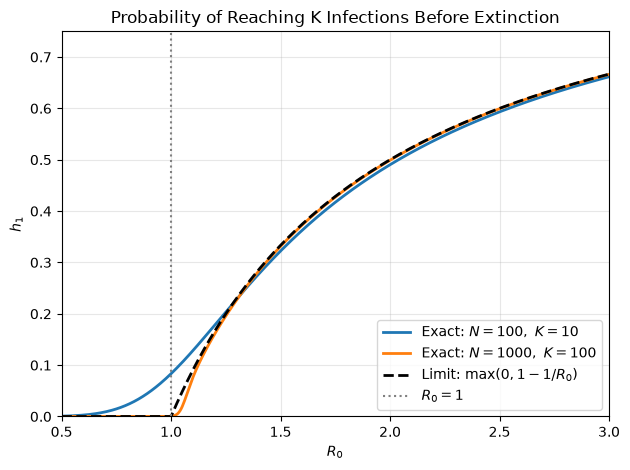

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def h1_exact(R0, N, K):
    rho = 1.0
    denom = 1.0

    for j in range(1, K):
        rho *= N / (R0 * (N - j))
        denom += rho

    return 1 / denom

R0_vals = np.linspace(0.5, 3, 500)

h1_N100 = np.array([h1_exact(R0, N = 100, K = 10) for R0 in R0_vals])
h1_N1000 = np.array([h1_exact(R0, N = 1000, K = 100) for R0 in R0_vals])

h1_lim = np.maximum(0, 1 - 1 / R0_vals)

#plot!
plt.plot(
    R0_vals,
    h1_N100,
    label = r"Exact: $N=100, \ K=10$",
    linewidth = 2
)

plt.plot(
    R0_vals,
    h1_N1000,
    label = r"Exact: $N=1000, \ K=100$",
    linewidth = 2
)

plt.plot(
    R0_vals,
    h1_lim,
    color = "black",
    linestyle = "--",
    label = r"Limit: $\max(0,1-1/R_0)$",
    linewidth = 2
)

plt.axvline(
    x = 1,
    color = "grey",
    linestyle = ":",
    label = r"$R_0=1$"
)

plt.xlabel(r"$R_0$")
plt.ylabel(r"$h_1$")
plt.title("Probability of Reaching K Infections Before Extinction")
plt.xlim(0.5, 3)
plt.ylim(0, 0.75)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.tight_layout()
plt.savefig("question_3c.png", dpi=300, bbox_inches="tight")
plt.show()

**Problem 3d**

In [7]:
N = 100
K = 10
gamma = 1
dt = 0.005
R0_values = [0.5, 0.8, 1.5, 3]

def expected_exit_time(R0):
    beta = R0 * gamma / N #Reverse engineered

    A = np.zeros((K - 1, K - 1))
    b = np.ones(K - 1)

    for n in range(1, K):
        p_n = beta * n * (N - n) * dt
        q_n = gamma * n * dt
        i = n - 1

        A[i, i] = p_n + q_n

        if n > 1:
            A[i, i - 1] = -q_n

        if n < K - 1:
            A[i, i + 1] = -p_n

    e = np.linalg.solve(A, b)
    return e

for R0 in R0_values:
    e = expected_exit_time(R0)
    print(f"R0 = {R0}: e1 * dt = {e[0] * dt : .4f}")


R0 = 0.5: e1 * dt =  1.3736
R0 = 0.8: e1 * dt =  1.7699
R0 = 1.5: e1 * dt =  1.7959
R0 = 3: e1 * dt =  0.9655


In [8]:
#Simulation
def simulated_exit_time(R0, sims = 100000, seed = 34):
    rng = np.random.default_rng(seed)
    beta = R0 * gamma / N
    exit_times = np.zeros(sims)

    for sim in range(sims):
        n = 1
        steps = 0

        while 0 < n < K:
            p_n = beta * n * (N - n) * dt
            q_n = gamma * n * dt
            u = rng.random()

            if u < p_n:
                n += 1

            elif u < p_n + q_n:
                n -= 1

            steps += 1

        exit_times[sim] = steps * dt

    return np.mean(exit_times)

R0_check = 1.5
sim_time = simulated_exit_time(R0_check)
exact_time = expected_exit_time(R0_check)[0] * dt

print(f"Exact time: {exact_time : .4f}")
print(f"Simulated time: {sim_time : .4f}")

            

Exact time:  1.7959
Simulated time:  1.7978
